# Big Data Analysis
## Spark SQL and window functions

Goal for today:
- Ask questions to a Spark table with SQL, and see the pandas equivalent of each clause
- Read a query in the order Spark runs it
- Combine tables with joins, and split long queries into steps with CTEs
- Use window functions to compare each row with its neighbours (previous year, running total, rank)
- Write your own Python function (UDF) and call it from SQL

How to use this notebook:
- Run it in Databricks, top to bottom
- Read each picture before the code below it: the code reproduces the picture
- Exercises are labelled Core, Practice or Challenge (optional)
- In each exercise, the steps and functions are listed; you write the code
- Focus on the question each query answers, not on memorising syntax

Dataset
- `housing.csv`: 545 houses with price, area, number of rooms, furnishing status and a few yes/no features (same as last week)
- `penn_world_table.parquet`: GDP, population and other economic indicators for 185 countries, 1950-2023 (window functions and exercises)

___

## 1) The big idea: asking questions to a table

SQL (Structured Query Language) is a fixed grammar for asking questions to a table: *which columns* (`SELECT`), *from which table* (`FROM`), *which rows* (`WHERE`), *per which group* (`GROUP BY`).

You already ask these questions in pandas. SQL is the same idea written as a sentence, and it is understood by almost every data tool: databases, Databricks, cloud data warehouses.

In Spark, SQL and the DataFrame code from week 5 are two ways of writing the same thing. Spark turns both into the same plan, and (as in weeks 4-5) nothing runs until an action such as `.show()` asks for the result.

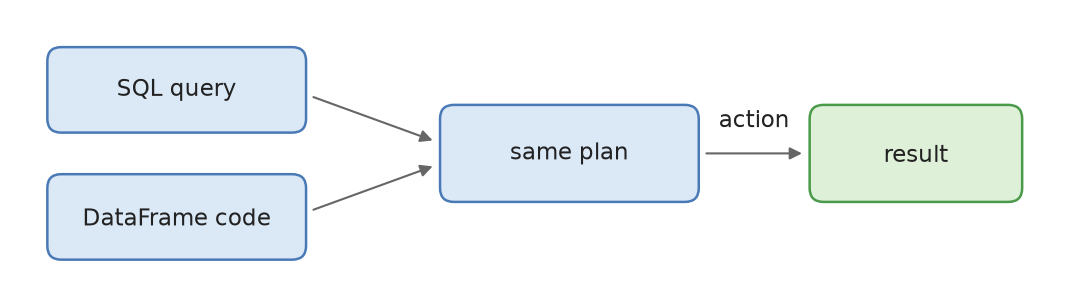

Each SQL clause has a pandas equivalent:

| SQL | pandas | Meaning |
|---|---|---|
| `SELECT price, area` | `df[["price", "area"]]` | keep some columns |
| `FROM housing` | `df` | which table |
| `WHERE price > 5000000` | `df[df["price"] > 5000000]` | keep some rows |
| `GROUP BY furnishingstatus` + `AVG(price)` | `df.groupby("furnishingstatus")["price"].mean()` | one summary row per group |
| `HAVING COUNT(*) > 50` | filter the result of the groupby | keep some groups |
| `ORDER BY price DESC` | `df.sort_values("price", ascending=False)` | sort |
| `LIMIT 10` | `.head(10)` | first rows only |
| `JOIN ... USING (key)` | `pd.merge(df1, df2, on="key")` | add columns from another table |

### 1.1 The order Spark runs a query

We write `SELECT` first, but Spark starts with `FROM`. Reading a query in this order makes it easier to understand and to debug:

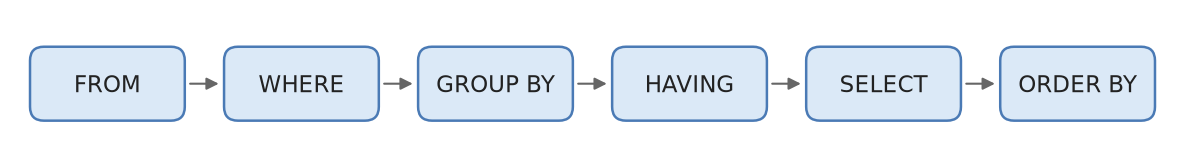

What should you notice?
- `WHERE` keeps or drops **rows**, before any grouping
- `GROUP BY` turns many rows into one row per group, and `HAVING` keeps or drops **groups**
- `SELECT` and `ORDER BY` only shape the final answer

___

## 2) Setup (pre-written, just run it)

Databricks already gives us a Spark session called `spark`; the cell below reuses it.

`DATA_DIR` is the folder this notebook is in (`os.getcwd()`). The data files sit next to the notebook, so this works in any copy of the repository, with no path to edit.

In [ ]:
# 2.1 Spark session and data paths
import os

from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("SparkSQL_Class").getOrCreate()

DATA_DIR = os.getcwd()
HOUSING_PATH = f"{DATA_DIR}/housing.csv"
PWT_PATH = f"{DATA_DIR}/penn_world_table.parquet"

### 2.2 Schemas: the column types of a table

A **schema** lists the name and type of every column, and whether it may be empty (`null`). It is what `df.dtypes` shows in pandas.

- `inferSchema=True` asks Spark to read the file once to guess the types, like `pd.read_csv` does. Easy, but it costs an extra pass over the data and can guess wrong (a column of numbers with one `"N/A"` becomes text)
- In production, people write the schema by hand so the types never change by surprise

```python
from pyspark.sql.types import StructType, StructField, IntegerType, StringType

schema = StructType([
    StructField("price",            IntegerType(), True),
    StructField("area",             IntegerType(), True),
    # ... one StructField per column ...
    StructField("furnishingstatus", StringType(),  True),
])
housing_df = spark.read.schema(schema).option("header", "true").csv(HOUSING_PATH)
```

> Today the file is small, so we use `inferSchema=True` and check the result with `printSchema()`.

In [ ]:
# 2.2 Load the housing data and check the inferred types
housing_df = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "true")
    .csv(HOUSING_PATH)
)

housing_df.printSchema()
print("Rows:", housing_df.count())

Check: you should see 13 columns (`price`, `area`, ..., `furnishingstatus`) and `Rows: 545`.

### 2.3 Give the table a name for SQL

SQL refers to tables by name. `createOrReplaceTempView` gives the DataFrame the name `housing` for this session. Nothing is copied or saved.

In [ ]:
# 2.3 Register the DataFrame as a SQL view called "housing"
housing_df.createOrReplaceTempView("housing")

___

## 3) Basic SQL queries

`spark.sql("...")` takes a query as text and returns a normal Spark DataFrame; `.show()` is the action that runs it.

> We write queries between triple quotes `""" ... """` so they can span several lines.

In [ ]:
# 3.1 A few columns, first 10 rows
# pandas: df[["price", "area", "bedrooms", "bathrooms", "furnishingstatus"]].head(10)
spark.sql("""
    SELECT price, area, bedrooms, bathrooms, furnishingstatus
    FROM   housing
    LIMIT  10
""").show()

In [ ]:
# 3.2 Count and basic statistics for the whole table
# pandas: df["price"].agg(["count", "mean", "min", "max"])
spark.sql("""
    SELECT
        COUNT(*)              AS total_rows,
        ROUND(AVG(price), 0)  AS avg_price,
        MIN(price)            AS min_price,
        MAX(price)            AS max_price
    FROM housing
""").show()

What should you notice?
- `AS` names a result column (like naming a new column in pandas)
- With no `GROUP BY`, `COUNT`, `AVG`, `MIN` and `MAX` summarise the whole table into one row

___

## 4) Filtering, aggregation and sorting

`WHERE`, `GROUP BY`, `HAVING` and `ORDER BY` work as in any database. The picture shows `GROUP BY furnishingstatus` on the first four houses of the file: four rows become one row per furnishing status, with a count and an average.

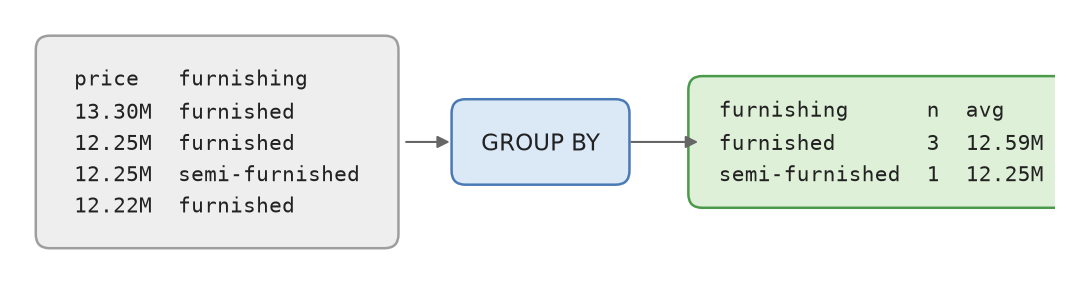

In [ ]:
# 4.1 WHERE + ORDER BY: furnished houses on the main road, most expensive first
# pandas: df[(df["furnishingstatus"] == "furnished") & (df["mainroad"] == "yes")].sort_values("price", ascending=False).head(10)
spark.sql("""
    SELECT price, area, bedrooms, bathrooms, parking
    FROM   housing
    WHERE  furnishingstatus = 'furnished'
      AND  mainroad = 'yes'
    ORDER  BY price DESC
    LIMIT  10
""").show()

In [ ]:
# 4.2 GROUP BY: number of houses and average price per number of bedrooms
# pandas: df.groupby("bedrooms")["price"].agg(["count", "mean"])
spark.sql("""
    SELECT
        bedrooms,
        COUNT(*)              AS num_houses,
        ROUND(AVG(price), 0)  AS avg_price
    FROM   housing
    GROUP  BY bedrooms
    ORDER  BY bedrooms
""").show()

What should you notice?
- Text values go in single quotes (`'furnished'`); column names have no quotes
- After `GROUP BY bedrooms`, `SELECT` can only show the group column and summaries (`COUNT`, `AVG`, ...)
- Some groups are tiny (houses with 6 bedrooms). An average of 2 houses is much less reliable than an average of 300. `HAVING` lets us drop small groups

## Exercise 1 (Core): houses per furnishing status

`GROUP BY` makes one row per group, `COUNT(*)` and `AVG()` summarise each group, `HAVING` keeps only the groups that pass a condition, and `ORDER BY ... DESC` sorts from highest to lowest.

**Goal:** For each furnishing status, compute the number of houses, the average price and the average area. Keep only the furnishing statuses with more than 50 houses, and sort by average price, highest first.

**Concepts:** `GROUP BY`, `COUNT(*)`, `AVG()`, `ROUND()`, `HAVING`, `ORDER BY ... DESC`

**Expected output:** a table with columns `furnishingstatus`, `num_houses`, `avg_price`, `avg_area_sqft` and 3 rows (all three statuses have more than 50 houses). `furnished` comes first: 140 houses, average price about 5,495,696.

In [ ]:
# Hints:
#   - Group by furnishingstatus
#   - Average price and average area, rounded to 0 decimals
#   - Keep groups with more than 50 houses: HAVING COUNT(*) > 50
#   - Sort by the average price, highest first

spark.sql("""
    -- YOUR QUERY HERE
""").show()

### 4.3 CASE WHEN: turning numbers into categories

`CASE WHEN` gives a label to each row depending on a condition, like `pd.cut` in pandas.

In [ ]:
# 4.3 Price tiers, then one row per tier
# pandas: pd.cut(df["price"], [0, 3_500_000, 6_000_000, 9_000_000, float("inf")], labels=[...])
spark.sql("""
    SELECT
        CASE
            WHEN price < 3500000 THEN 'Budget'
            WHEN price < 6000000 THEN 'Mid-range'
            WHEN price < 9000000 THEN 'Premium'
            ELSE                      'Luxury'
        END                  AS price_tier,
        COUNT(*)             AS count,
        ROUND(AVG(area), 0)  AS avg_area_sqft
    FROM   housing
    GROUP  BY price_tier
    ORDER  BY avg_area_sqft DESC
""").show()

Discussion: the limits 3.5M, 6M and 9M were chosen by hand. What happens to the table if we move them? Is "Luxury" a property of the house, or of our choice of limits?

___

## 5) Joins: adding columns from another table

A join matches the rows of two tables on a shared column (the *key*), like `pd.merge` in pandas. Spark SQL supports `INNER`, `LEFT`, `RIGHT`, `FULL OUTER`, `CROSS`, `SEMI` and `ANTI` joins.

We create a small table with an amenity score per furnishing status, and add it to every house:

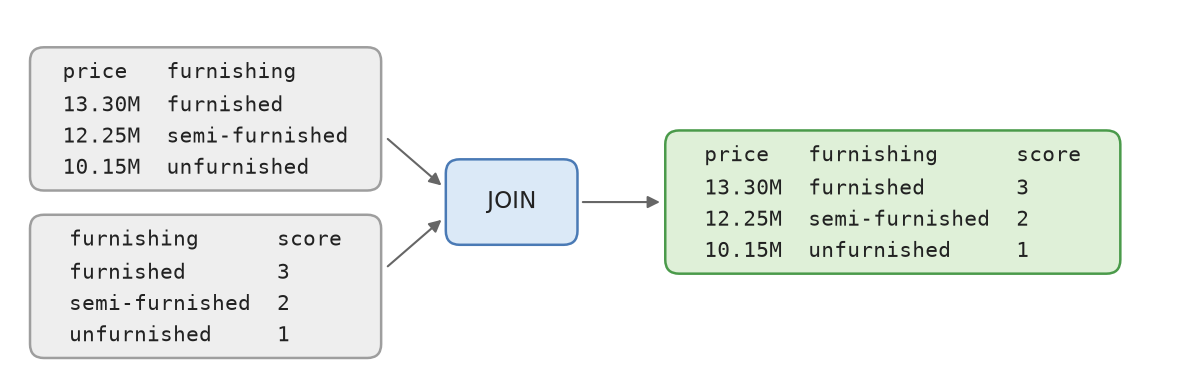

In [ ]:
# 5.1 A small lookup table: one amenity score per furnishing status
amenities_data = [
    ("furnished",      3, "All appliances and furniture provided"),
    ("semi-furnished", 2, "Basic furniture only"),
    ("unfurnished",    1, "Empty shell, bring your own"),
]
amenities_schema = ["furnishingstatus", "amenity_score", "description"]

amenities_df = spark.createDataFrame(amenities_data, schema=amenities_schema)
amenities_df.createOrReplaceTempView("amenities")
amenities_df.show(truncate=False)

In [ ]:
# 5.2 INNER JOIN: every house gets the score of its furnishing status
# pandas: pd.merge(housing, amenities, on="furnishingstatus")
spark.sql("""
    SELECT
        h.price,
        h.area,
        h.bedrooms,
        h.furnishingstatus,
        a.amenity_score,
        a.description
    FROM   housing   h
    JOIN   amenities a USING (furnishingstatus)
    ORDER  BY h.price DESC
    LIMIT  8
""").show(truncate=False)

`h` and `a` are short nicknames (aliases) for the two tables: `h.price` means "price from housing".

What if the lookup table is incomplete? Below, the score for `unfurnished` is missing, and we compare an INNER join (`how="inner"` in pandas) with a LEFT join (`how="left"`).

In [ ]:
# 5.3 INNER vs LEFT join when the lookup table has no row for "unfurnished"
spark.createDataFrame(
    [("furnished", 3), ("semi-furnished", 2)],
    schema=["furnishingstatus", "amenity_score"],
).createOrReplaceTempView("amenities_partial")

spark.sql("""
    SELECT 'inner join' AS join_type, COUNT(*) AS houses_kept
    FROM   housing JOIN amenities_partial USING (furnishingstatus)
    UNION ALL
    SELECT 'left join', COUNT(*)
    FROM   housing LEFT JOIN amenities_partial USING (furnishingstatus)
""").show()

In [ ]:
# 5.4 LEFT JOIN with COALESCE: unmatched houses get 0 instead of NULL
spark.sql("""
    SELECT
        h.price,
        h.furnishingstatus,
        COALESCE(a.amenity_score, 0) AS amenity_score
    FROM   housing h
    LEFT   JOIN amenities_partial a USING (furnishingstatus)
    WHERE  h.furnishingstatus = 'unfurnished'
    LIMIT  5
""").show()

What should you notice?
- The INNER join silently dropped every unfurnished house (545 - 367 = 178 houses). No error, no warning
- The LEFT join keeps all 545 houses; the unmatched ones get `NULL` (empty) in `amenity_score`
- `COALESCE(x, 0)` replaces `NULL` by 0, like `fillna(0)` in pandas. Only do it if 0 really means "none"

Discussion: after a join, how would you check that no rows were lost by accident?

___

## 6) Common Table Expressions (CTEs): a query in named steps

A **CTE** gives a name to an intermediate result with `WITH name AS (...)`. In pandas you would save each step in a variable (`step1 = ...`, `step2 = step1...`); a CTE does the same inside one query.

```sql
WITH step1 AS (SELECT ... FROM housing ...),
     step2 AS (SELECT ... FROM step1 ...)
SELECT * FROM step2
```

- **Readability:** each step has a name, instead of queries nested inside queries
- **Reuse:** a step can be used several times in the same query
- **Debugging:** you can run the inner `SELECT` of a step on its own

Nothing is saved: the CTE only exists while the query runs, and Spark recomputes it each time unless it is cached (section 7).

In [ ]:
# 6.1 Which bedroom counts have an average price above the overall average?
spark.sql("""
    WITH avg_by_bedrooms AS (
        SELECT
            bedrooms,
            ROUND(AVG(price), 0)  AS avg_price,
            COUNT(*)              AS num_houses
        FROM   housing
        GROUP  BY bedrooms
    ),
    overall AS (
        SELECT ROUND(AVG(price), 0) AS overall_avg FROM housing
    )
    SELECT
        a.bedrooms,
        a.avg_price,
        a.num_houses,
        o.overall_avg,
        ROUND((a.avg_price - o.overall_avg) / o.overall_avg * 100, 1) AS pct_above_avg
    FROM   avg_by_bedrooms a
    CROSS  JOIN overall o
    WHERE  a.avg_price > o.overall_avg
    ORDER  BY a.avg_price DESC
""").show()

What should you notice?
- `avg_by_bedrooms` has one row per bedroom count; `overall` has a single row with the overall average
- `CROSS JOIN` attaches that single row to every row of `avg_by_bedrooms`, so we can compare them
- 6 bedrooms appears "above average" with only 2 houses: always look at the group size

___

## 7) Caching tables

Spark is lazy: every time you query a view, it recomputes it from the file. **Caching** keeps the result in memory so the next queries skip that work, like keeping an ingredient you use often on the counter instead of in the cupboard.

| Command | Storage | When to use |
|---|---|---|
| `CACHE TABLE t` | memory | you will query `t` many times |
| `CACHE TABLE t OPTIONS('storageLevel' 'DISK_ONLY')` | disk | the table is too large for memory |
| `UNCACHE TABLE t` | - | free the memory when you are done |

- Caching only helps when the same table is queried **several times**. A job that reads the data once wastes memory by caching it
- Databricks **serverless** compute does not allow `CACHE TABLE`, so we do not run it here. It works on classic Databricks clusters and on a local Spark installation

___

## 8) Partitioning

**Partitioning** writes a table as one folder per value of a column. A query that filters on that column opens only the matching folder and skips the others (*partition pruning*), like a filing cabinet with one drawer per category: to find furnished houses, open one drawer.

```
housing_partitioned/
    furnishingstatus=furnished/          <- WHERE furnishingstatus = 'furnished'
        part-0000.parquet                   only this folder is read
    furnishingstatus=semi-furnished/
        part-0000.parquet
    furnishingstatus=unfurnished/
        part-0000.parquet
```

> **Bucketing** is a related idea: rows are spread over a fixed number of files by a hash of a column, which saves work in later joins and groupings on that column.

Week 7 covers partitioned files in detail. Serverless compute can only write to Unity Catalog tables, so we save the partitioned data as a table.

In [ ]:
# 8.1 Write the housing table partitioned by furnishing status
TABLE = "workspace.default.housing_partitioned_lab"

(
    housing_df
    .write
    .partitionBy("furnishingstatus")
    .mode("overwrite")          # replaces the data from a previous run
    .saveAsTable(TABLE)
)

# Read it back: Spark finds the partitions by itself
partitioned_df = spark.read.table(TABLE)
partitioned_df.createOrReplaceTempView("housing_partitioned")

print("Partitions on disk:")
spark.sql(f"SHOW PARTITIONS {TABLE}").show(truncate=False)

In [ ]:
# 8.2 Partition pruning: only the 'furnished' partition is read
spark.sql("""
    SELECT COUNT(*), ROUND(AVG(price), 0) AS avg_price
    FROM   housing_partitioned
    WHERE  furnishingstatus = 'furnished'
""").show()

In [ ]:
# 8.3 The physical plan: look for 'PartitionFilters'
spark.sql("""
    SELECT COUNT(*) FROM housing_partitioned
    WHERE  furnishingstatus = 'furnished'
""").explain("simple")

___

## 9) Window functions

Sometimes we need a value **for each row** that depends on **the other rows of its group**:
- each country's average GDP written next to every year
- the change from the previous year
- a running total, or a rank within the group

`GROUP BY` cannot do this, because it collapses each group into one row. A **window function** computes over a group of rows (the *window*) but **keeps every row**.

```sql
function(...) OVER (
    PARTITION BY col1        -- the groups (like GROUP BY, but rows are kept)
    ORDER BY     col2        -- the order of rows inside each group
    ROWS BETWEEN ...         -- optional: which neighbouring rows to use (the frame)
)
```

| SQL window | pandas equivalent |
|---|---|
| `AVG(x) OVER (PARTITION BY g)` | `df.groupby("g")["x"].transform("mean")` |
| `LAG(x, 1) OVER (PARTITION BY g ORDER BY t)` | `df.sort_values("t").groupby("g")["x"].shift(1)` |
| `SUM(x) OVER (... ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)` | `groupby("g")["x"].cumsum()` |
| `AVG(x) OVER (... ROWS BETWEEN 2 PRECEDING AND CURRENT ROW)` | `groupby("g")["x"].rolling(3).mean()` |
| `ROW_NUMBER() OVER (PARTITION BY g ORDER BY x DESC)` | `groupby("g")["x"].rank(method="first", ascending=False)` |

### 9.1 A few rows of the Penn World Table

Windows are easiest to see over time. We load the Penn World Table (also used in the exercises) and keep Portugal and Spain, 2015-2019. `gdp_pc` is GDP per person in US dollars (`rgdpe / pop`, see section 11).

In [ ]:
# 9.1 Load the Penn World Table and keep a few rows
pwt_df = spark.read.parquet(PWT_PATH)
pwt_df.createOrReplaceTempView("pwt")

spark.sql("""
    CREATE OR REPLACE TEMP VIEW pwt_small AS
    SELECT country, year, ROUND(rgdpe / pop, 0) AS gdp_pc
    FROM   pwt
    WHERE  countrycode IN ('PRT', 'ESP')
      AND  year BETWEEN 2015 AND 2019
""")

spark.sql("SELECT * FROM pwt_small ORDER BY country, year").show()

### 9.2 GROUP BY versus a window

The picture uses 2018 and 2019 only. `GROUP BY` collapses each country into one row; the window (`OVER`) writes the country average next to every year:

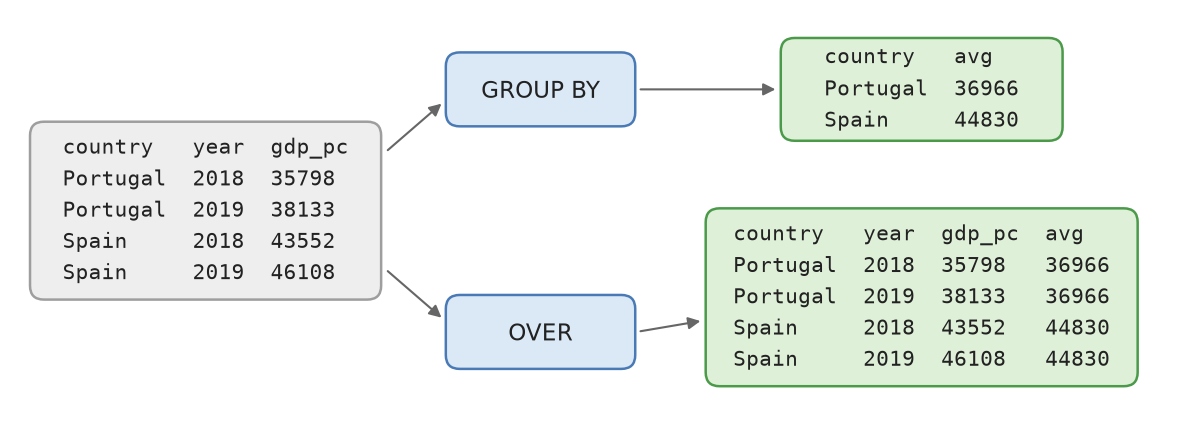

In [ ]:
# 9.2 Same question, two answers (2018-2019 only, as in the picture)
# GROUP BY: one row per country
spark.sql("""
    SELECT country, ROUND(AVG(gdp_pc), 0) AS avg
    FROM   pwt_small
    WHERE  year >= 2018
    GROUP  BY country
""").show()

# Window: one row per country and year, with the country average added
spark.sql("""
    SELECT country, year, gdp_pc,
           ROUND(AVG(gdp_pc) OVER (PARTITION BY country), 0) AS avg
    FROM   pwt_small
    WHERE  year >= 2018
    ORDER  BY country, year
""").show()

Check: both results match the picture (Portugal 36966, Spain 44830).

### 9.3 Ordered windows: previous row, running total, moving average

Once the rows of each country are ordered by year, each row can look at its neighbours. For Portugal in 2018 (green in the picture), `LAG` reads the value of 2017, and a frame of "2 preceding rows and the current row" covers 2016-2018:

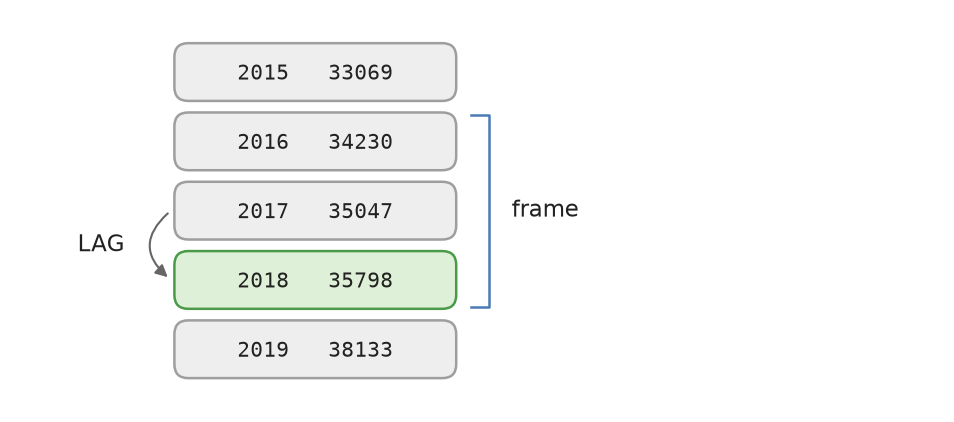

In [ ]:
# 9.3 Change from the previous year, running total and 3-year moving average
spark.sql("""
    SELECT
        country, year, gdp_pc,
        LAG(gdp_pc, 1) OVER (PARTITION BY country ORDER BY year)           AS prev_gdp_pc,
        gdp_pc - LAG(gdp_pc, 1) OVER (PARTITION BY country ORDER BY year)  AS change,
        SUM(gdp_pc) OVER (PARTITION BY country ORDER BY year
                          ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS running_total,
        ROUND(AVG(gdp_pc) OVER (PARTITION BY country ORDER BY year
                                ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 0) AS moving_avg_3
    FROM   pwt_small
    ORDER  BY country, year
""").show()

What should you notice?
- 2015 has no previous year, so `prev_gdp_pc` and `change` are `NULL` (empty), not 0
- The windows start again for Spain: Spain 2015 never looks back at Portugal 2019. That is what `PARTITION BY` is for
- Portugal 2018: previous year 35047, change 751, moving average of 2016-2018 = 35025

Common window functions:

| Function | Purpose |
|---|---|
| `ROW_NUMBER()` | position 1, 2, 3, ... (no ties) |
| `RANK()` | rank with gaps after ties |
| `DENSE_RANK()` | rank without gaps |
| `LAG(col, n)` / `LEAD(col, n)` | value n rows before / after the current row |
| `SUM / AVG / MIN / MAX` | running or moving summaries |
| `NTILE(n)` | split the rows into n groups of equal size |
| `PERCENT_RANK()` | position as a fraction between 0 and 1 |

### 9.4 Window functions on the houses

In [ ]:
# 9.4 ROW_NUMBER: the 3 most expensive houses in each furnishing category
spark.sql("""
    WITH ranked AS (
        SELECT
            price, area, bedrooms, furnishingstatus,
            ROW_NUMBER() OVER (
                PARTITION BY furnishingstatus
                ORDER BY price DESC
            ) AS rank_in_category
        FROM housing
    )
    SELECT *
    FROM   ranked
    WHERE  rank_in_category <= 3
    ORDER  BY furnishingstatus, rank_in_category
""").show()

We cannot write `WHERE rank_in_category <= 3` in the same query as the window, because `WHERE` runs before `SELECT` (see the run order in section 1.1). So we compute the window in a CTE and filter in the outer query. This is the standard pattern.

In [ ]:
# 9.5 Running total and 5-row moving average of price, ordered by area
spark.sql("""
    SELECT
        price,
        area,
        bedrooms,
        SUM(price) OVER (ORDER BY area
                         ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)  AS running_total_price,
        ROUND(AVG(price) OVER (ORDER BY area
                               ROWS BETWEEN 4 PRECEDING AND CURRENT ROW), 0) AS moving_avg_5
    FROM  housing
    ORDER BY area
    LIMIT 15
""").show()

In [ ]:
# 9.6 NTILE: split houses into price quartiles (1 = cheapest 25%)
spark.sql("""
    SELECT
        price,
        area,
        furnishingstatus,
        NTILE(4) OVER (ORDER BY price) AS price_quartile
    FROM  housing
    ORDER BY price
    LIMIT 20
""").show()

In [ ]:
# 9.7 LAG / LEAD: compare each house price with its neighbours in price order
spark.sql("""
    SELECT
        price,
        area,
        LAG(price, 1)  OVER (ORDER BY price) AS prev_price,
        LEAD(price, 1) OVER (ORDER BY price) AS next_price,
        price - LAG(price, 1) OVER (ORDER BY price) AS gap_from_prev
    FROM  housing
    ORDER BY price
    LIMIT 15
""").show()

Discussion: would these queries still work with 100 million rows?

___

## 10) User-Defined Functions (UDFs)

When SQL has no built-in function for what you need, you can write a normal Python function and register it as a **UDF**, so SQL can call it on every row. It is the Spark version of `df["price"].apply(my_function)` in pandas.

```
  Spark (runs on the JVM)  --- one value at a time --->  your Python function
                           <------- result ------------
```

> **Performance:** a Python UDF sends every value from Spark to Python and back. Prefer built-in SQL functions (like `CASE WHEN`) when they can do the job. If you do need Python, **Pandas UDFs** (`@pandas_udf`) send whole columns at once and are usually 10-100x faster.

### 10.1 Scalar UDF

In [ ]:
# 10.1 A scalar UDF: price -> tier label
from pyspark.sql.types import StringType, DoubleType

def price_label(price):
    """Return a human-readable price tier label."""
    if price is None:
        return "Unknown"
    if price < 3_500_000:
        return "Budget"
    if price < 6_000_000:
        return "Mid-range"
    if price < 9_000_000:
        return "Premium"
    return "Luxury"

# Register the function under a name SQL can use, with the type it returns
spark.udf.register("price_label", price_label, StringType())

spark.sql("""
    SELECT
        price,
        price_label(price) AS tier,
        area,
        bedrooms
    FROM housing
    LIMIT 12
""").show()

What should you notice?
- The function deals with `None` (an empty value) first: real data always has a missing value somewhere
- This UDF gives the same tiers as the `CASE WHEN` in 4.3, so here the built-in would be the better choice. A UDF pays off for rules that are hard to write in SQL

### 10.2 Pandas UDF (vectorised)

A Pandas UDF receives a whole column as a `pandas.Series` and returns a `Series`, so you can use normal pandas operations inside it.

In [ ]:
# 10.2 A Pandas UDF: price per square foot, computed on whole columns
import pandas as pd
from pyspark.sql.functions import pandas_udf

@pandas_udf(DoubleType())
def price_per_sqft(price: pd.Series, area: pd.Series) -> pd.Series:
    """Price per square foot, computed on entire columns at once."""
    return (price / area).round(2)

spark.udf.register("price_per_sqft", price_per_sqft)

spark.sql("""
    SELECT
        price,
        area,
        price_per_sqft(price, area) AS ppsf,
        furnishingstatus
    FROM housing
    ORDER BY ppsf DESC
    LIMIT 10
""").show()

### 10.3 Combining UDFs with window functions

In [ ]:
# 10.3 UDF results used inside a window: average price per sq ft per furnishing status
spark.sql("""
    SELECT
        price,
        area,
        furnishingstatus,
        price_label(price)           AS tier,
        price_per_sqft(price, area)  AS ppsf,
        ROUND(
          AVG(price_per_sqft(price, area))
              OVER (PARTITION BY furnishingstatus), 2
        )                            AS avg_ppsf_by_furnishing
    FROM housing
    ORDER BY furnishingstatus, ppsf DESC
    LIMIT 15
""").show()

___

## 11) Exercises: Penn World Table

The **Penn World Table** (PWT 11.0) is a widely used economic dataset: GDP adjusted for price differences between countries, population, employment and productivity for 185 countries from 1950 to 2023. There is one row per country per year.

The file is in **Parquet**, a column-based format and the usual storage format in Spark: it keeps the column types and is much faster to read than CSV (week 7).

**Key columns used in the exercises**

| Column | Description |
|---|---|
| `countrycode` | ISO 3-letter code |
| `country` | Country name |
| `year` | Year (1950-2023) |
| `rgdpe` | Real GDP (expenditure side), **millions** of 2017 US dollars |
| `rgdpo` | Real GDP (output side), millions of 2017 US dollars |
| `pop` | Population, **millions** |
| `emp` | Number of people employed, millions |
| `hc` | Human capital index (from years of schooling), about 1 to 4 |
| `ctfp` | Productivity relative to the United States (USA = 1) |
| `labsh` | Share of national income paid to workers (0 to 1) |

> Units: `rgdpe / pop` = (millions of dollars) / (millions of people) = **dollars per person**. The millions cancel out.

In [ ]:
# 11.1 The Penn World Table (loaded in 9.1 as the view "pwt")
print(f"Rows: {pwt_df.count():,}  |  Columns: {len(pwt_df.columns)}")
pwt_df.select("countrycode", "country", "year", "rgdpe", "pop", "hc", "labsh").show(5)

## Exercise 2 (Core): GDP per person ranking

`WHERE` keeps the rows of one year and of large enough countries, a computed column (`rgdpe / pop AS ...`) creates a new value per row, and `ORDER BY ... DESC` with `LIMIT` keeps the top of the ranking.

**Goal:** Find the 10 countries with the highest GDP per person in 2019. Only include countries with at least 1 million inhabitants and a known GDP.

**Concepts:** `WHERE`, computed columns, `ROUND()`, `ORDER BY ... DESC`, `LIMIT`

**Expected output:** 10 rows with columns `country`, `countrycode`, `gdp_per_capita_usd`, `pop_millions`. Qatar comes first with about 113,745 dollars per person, then Ireland and Singapore.

In [ ]:
# Hints:
#   - GDP per person = rgdpe / pop (in dollars per person), rounded to 0 decimals
#   - Filter: year = 2019 AND pop >= 1 AND rgdpe IS NOT NULL
#   - Order by GDP per person, highest first, and keep 10 rows

spark.sql("""
    -- YOUR QUERY HERE
""").show(10, truncate=False)

Discussion: GDP per person is often used to say how well people live in a country. What does it actually measure, and what does it leave out? Look at the top 10: what do several of these countries have in common?

## Exercise 3 (Practice): average yearly GDP growth since 1990

`LAG()` with `PARTITION BY countrycode ORDER BY year` gives last year's value for the same country, `NULLIF(x, 0)` turns 0 into `NULL` to avoid dividing by zero, and `HAVING` keeps only the countries with enough years.

**Goal:** For each country, compute the growth of GDP from one year to the next, using the years from 1990 on. Then find the 10 countries with the highest average yearly growth, among those with at least 20 years of growth values.

**Concepts:** `LAG()`, `NULLIF`, CTE (`WITH`), `GROUP BY`, `HAVING`, `ORDER BY`

**Expected output:** 10 rows with columns `country`, `avg_growth_pct`, `years_of_data`. Equatorial Guinea comes first with about 15.65% per year, then Qatar (about 11.97%).

In [ ]:
# Hints:
#   - Step 1 (in a CTE): yoy_growth = (rgdpe - prev_rgdpe) / NULLIF(prev_rgdpe, 0),
#     where prev_rgdpe = LAG(rgdpe) OVER (PARTITION BY countrycode ORDER BY year)
#   - Keep only years >= 1990 and rgdpe IS NOT NULL
#   - Step 2 (outer query): drop the NULL growth values, GROUP BY country,
#     average growth in % (x 100, rounded to 2 decimals), HAVING COUNT(*) >= 20
#   - Order by average growth, highest first

spark.sql("""
    -- YOUR QUERY HERE
""").show(10, truncate=False)

Discussion: the rule "at least 20 years of data" removes some countries. Which countries are likely to have short records, and how could that change the ranking?

## Exercise 4 (Practice): classify countries with a UDF

`spark.udf.register(name, function, return_type)` turns a Python function into a SQL function, which you can then use in `SELECT` and `GROUP BY` like any built-in function.

**Goal:** Write a Python function `wealth_tier` that maps GDP per person (in dollars) to a label, register it as a UDF, and use it to count how many countries fall into each tier in 2019 (countries with at least 1 million inhabitants), with the average GDP per person per tier, highest first.

**Thresholds** (dollars per person): `< 5,000` Low | `5,000-20,000` Middle | `20,000-60,000` High | `>= 60,000` Very High

**Concepts:** Python function with `if`/`return`, `spark.udf.register`, calling a UDF in SQL, `GROUP BY`

**Expected output:** 4 rows with columns `tier`, `num_countries`, `avg_gdp_per_capita_usd`, from Very High (14 countries) to Low (34 countries).

In [ ]:
from pyspark.sql.types import StringType

# Step 1 -- Write a Python function wealth_tier(gdp_per_capita) that returns "Low", "Middle", "High"
#           or "Very High" using the thresholds above (and "Unknown" if the value is None).
# Step 2 -- Register it: spark.udf.register("wealth_tier", wealth_tier, StringType())
# Step 3 -- Write the query below.

# Hints:
#   - GDP per person = rgdpe / pop; filter year = 2019 AND pop >= 1 AND rgdpe IS NOT NULL
#   - wealth_tier(rgdpe / pop) AS tier, then GROUP BY tier
#   - COUNT(*) and the average GDP per person (rounded to 0) per tier, highest average first

spark.sql("""
    -- YOUR QUERY HERE
""").show(truncate=False)

## Exercise 5 (Practice): GDP per person over time, in two steps

A **temp view** (`CREATE OR REPLACE TEMP VIEW name AS SELECT ...`) saves a query under a name for the whole session, so later queries can use it like a table. It is like saving an intermediate pandas DataFrame in a variable.

**Goal:** Step 1: create a view with each country's GDP per person for every year, plus the previous year's value (with `LAG`). Step 2: from that view, find the 10 countries with the highest average yearly increase in GDP per person since 2000.

**Concepts:** `CREATE OR REPLACE TEMP VIEW`, `LAG`, `GROUP BY`, `ORDER BY`

**Expected output:** 10 rows with columns `country`, `avg_annual_increase`, `years_of_data`. Qatar comes first with an average increase of about 3,741 dollars per person per year, then Ireland and Singapore.

In [ ]:
# Step 1 -- Create a view gdp_pc with country, countrycode, year, the GDP per person (rgdpe / pop)
#           and the previous year's value:
#           LAG(rgdpe / pop) OVER (PARTITION BY countrycode ORDER BY year) AS prev_gdp_per_capita
# Hint:     spark.sql("CREATE OR REPLACE TEMP VIEW gdp_pc AS SELECT ...")
#           keep only rows where rgdpe and pop are not NULL

# Step 2 -- Query the view: for year >= 2000 and a known previous value,
#           average of (gdp_per_capita - prev_gdp_per_capita) per country (rounded to 0),
#           the number of years, ordered from the largest increase, top 10

spark.sql("""
    -- YOUR QUERY HERE
""").show(10, truncate=False)

Discussion: Exercise 3 ranked countries by growth in **%**, Exercise 5 by growth in **dollars**. Why are the two top 10 lists so different? Which one would you use to say which economy "grew the most"?

## Exercise 6 (Challenge (optional)): human capital score with a Pandas UDF

`@pandas_udf(DoubleType())` turns a function on `pandas.Series` into a Spark function, and `PERCENT_RANK() OVER (ORDER BY ...)` gives each row its position from 0 (lowest) to 1 (highest).

**Goal:** Register a Pandas UDF `hc_score(hc, labsh)` that returns `0.6 * hc + 0.4 * labsh`. Then compute this score for each country in 2019 and its `PERCENT_RANK()` over all countries. Show the top 15.

**Concepts:** `@pandas_udf`, `spark.udf.register`, `PERCENT_RANK()` as a window function, `ORDER BY`

**Expected output:** 15 rows with columns `country`, `score`, `pct_rank`. The United Kingdom comes first (score about 2.507, `pct_rank` 1.0).

In [ ]:
import pandas as pd
from pyspark.sql.functions import pandas_udf
from pyspark.sql.types import DoubleType

# Step 1 -- Define a @pandas_udf(DoubleType()) function hc_score(hc: pd.Series, labsh: pd.Series)
#           that returns (0.6 * hc + 0.4 * labsh), rounded to 4 decimals.
# Step 2 -- Register it: spark.udf.register("hc_score", hc_score)
# Step 3 -- Write the query below.

# Hints:
#   - PERCENT_RANK() OVER (ORDER BY hc_score(hc, labsh)), rounded to 3 decimals
#   - Filter: year = 2019 AND hc IS NOT NULL AND labsh IS NOT NULL
#   - Order by score, highest first; LIMIT 15

spark.sql("""
    -- YOUR QUERY HERE
""").show(15, truncate=False)

Discussion: `hc` goes from about 1 to 4, `labsh` from 0 to 1. Do the weights 0.6 and 0.4 really give `labsh` 40% of the influence on the score?

___

## 12) Summary

- SQL asks questions to a table in a fixed grammar; each clause has a pandas equivalent
- Spark turns SQL and DataFrame code into the same lazy plan
- Read a query in run order: FROM, WHERE, GROUP BY, HAVING, SELECT, ORDER BY
- `WHERE` filters rows, `HAVING` filters groups; an INNER join can silently drop unmatched rows
- CTEs and temp views split a long query into named steps
- Window functions compute within a group but keep every row: previous year, running total, rank
- UDFs add your own Python rules to SQL, at a speed cost; Pandas UDFs reduce that cost

Next week: CSV versus Parquet, and partitioned datasets (the filing cabinet from section 8).